# Stage 5 — District Clustering
## AgriShift: Agricultural Diversification & Crop Pattern Intelligence in India

**Goal:** group district-year observations with similar crop-area portfolios. This identifies broad patterns; it does not recommend crops or explain why districts grow them.

### Method
- Use the district-year crop-share matrix created in Stage 3.
- Exclude 2015 because the source contains only a small, incomplete subset of India for that year.
- Use available observations from 1997–2014. Coverage remains unbalanced across years.
- Apply the square-root (Hellinger) transformation to crop shares, then compare K-Means solutions for k = 2–8 using inertia and silhouette score.
- Use PCA only for a 2-D visualisation; clustering uses the full transformed crop-share matrix.

**Limitations:** district-name matches do not prove unchanged boundaries. Crop area summed across seasons is gross reported crop area, not unique physical land area.

## 1. Imports and project paths
Run this notebook from the AgriShift project root in VS Code. If scikit-learn is missing, install it in the notebook's Python environment with `pip install scikit-learn`.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore", category=FutureWarning)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

CROP_MATRIX_PATH = DATA_DIR / "district_year_crop_share_matrix.csv"
FEATURES_PATH = DATA_DIR / "district_year_diversification_features.csv"
if not CROP_MATRIX_PATH.exists():
    raise FileNotFoundError("Missing data/processed/district_year_crop_share_matrix.csv. Complete Stage 3 first.")
print("Project root:", PROJECT_ROOT)
print("Crop-share matrix exists:", CROP_MATRIX_PATH.exists())
print("Feature table exists:", FEATURES_PATH.exists())

Project root: c:\Users\ajadi\OneDrive\Desktop\CSD\Exploration\AgriShift
Crop-share matrix exists: True
Feature table exists: True


## 2. Load and inspect the crop-share matrix

In [3]:
crop_matrix = pd.read_csv(CROP_MATRIX_PATH)
print("Shape:", crop_matrix.shape)
display(crop_matrix.head())
print(crop_matrix.columns.tolist())

Shape: (9839, 119)


,State_Name,District_Name,Crop_Year,Apple,Arecanut,Arhar/Tur,Ash Gourd,Bajra,Banana,Barley,...,Turmeric,Turnip,Urad,Varagu,Water Melon,Wheat,Yam,other fibres,other misc. pulses,other oilseeds
0,Andaman and Nicobar Islands,NICOBARS,2000,0.0,0.061159,0.0,0.0,0.0,0.008584,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
1,Andaman and Nicobar Islands,NICOBARS,2001,0.0,0.061755,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
2,Andaman and Nicobar Islands,NICOBARS,2002,0.0,0.059487,0.0,0.0,0.0,0.010072,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
3,Andaman and Nicobar Islands,NICOBARS,2003,0.0,0.060560,0.0,0.0,0.0,0.012775,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000202
4,Andaman and Nicobar Islands,NICOBARS,2004,0.0,0.061019,0.0,0.0,0.0,0.003205,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000048


['State_Name', 'District_Name', 'Crop_Year', 'Apple', 'Arecanut', 'Arhar/Tur', 'Ash Gourd', 'Bajra', 'Banana', 'Barley', 'Bean', 'Beans & Mutter(Vegetable)', 'Beet Root', 'Ber', 'Bhindi', 'Bitter Gourd', 'Black pepper', 'Blackgram', 'Bottle Gourd', 'Brinjal', 'Cabbage', 'Cardamom', 'Carrot', 'Cashewnut', 'Castor seed', 'Cauliflower', 'Citrus Fruit', 'Coconut', 'Coffee', 'Colocosia', 'Cond-spcs other', 'Coriander', 'Cotton(lint)', 'Cowpea(Lobia)', 'Cucumber', 'Drum Stick', 'Dry chillies', 'Dry ginger', 'Garlic', 'Ginger', 'Gram', 'Grapes', 'Groundnut', 'Guar seed', 'Horse-gram', 'Jack Fruit', 'Jobster', 'Jowar', 'Jute', 'Jute & mesta', 'Kapas', 'Khesari', 'Korra', 'Lab-Lab', 'Lemon', 'Lentil', 'Linseed', 'Litchi', 'Maize', 'Mango', 'Masoor', 'Mesta', 'Moong(Green Gram)', 'Moth', 'Niger seed', 'Onion', 'Orange', 'Other Cereals & Millets', 'Other Citrus Fruit', 'Other Dry Fruit', 'Other Fresh Fruits', 'Other Kharif pulses', 'Other Rabi pulses', 'Other Vegetables', 'Papaya', 'Peach', 'Pear

## 3. Identify keys and crop-share columns
The notebook identifies the three ID columns and treats all remaining columns as crop shares. It checks that shares are numeric, non-negative, and sum to approximately 1.

In [4]:
key_columns = ["State_Name", "District_Name", "Crop_Year"]
missing_keys = [c for c in key_columns if c not in crop_matrix.columns]
if missing_keys:
    raise KeyError(f"Missing identifier columns: {missing_keys}")
crop_columns = [c for c in crop_matrix.columns if c not in key_columns]
if not crop_columns:
    raise ValueError("No crop-share columns found.")
crop_matrix["Crop_Year"] = pd.to_numeric(crop_matrix["Crop_Year"], errors="coerce")
crop_matrix[crop_columns] = crop_matrix[crop_columns].apply(pd.to_numeric, errors="coerce")
if crop_matrix[crop_columns].isna().any().any():
    raise ValueError("Missing or non-numeric crop-share values found.")
if (crop_matrix[crop_columns] < 0).any().any():
    raise ValueError("Negative crop shares found.")
row_sums = crop_matrix[crop_columns].sum(axis=1)
print("Crop categories:", len(crop_columns))
print("Minimum/maximum row share sum:", row_sums.min(), row_sums.max())
print("Rows outside 0.99–1.01:", ((row_sums < 0.99) | (row_sums > 1.01)).sum())
if not np.allclose(row_sums, 1.0, atol=0.01):
    raise ValueError("Crop-share rows do not sum approximately to 1. Check Stage 3.")

Crop categories: 116
Minimum/maximum row share sum: 0.9999999999999996 1.0000000000000007
Rows outside 0.99–1.01: 0


## 4. Select the analysis period
2015 is excluded because only two states are represented in the source that year. The 1997–2014 data are still unbalanced: not every district appears in every year.

In [5]:
analysis_df = crop_matrix.loc[crop_matrix["Crop_Year"].between(1997, 2014)].copy()
print("Rows in full matrix:", len(crop_matrix))
print("Rows used:", len(analysis_df))
print("Years included:", sorted(analysis_df["Crop_Year"].dropna().astype(int).unique()))
print("2015 rows excluded:", (crop_matrix["Crop_Year"] == 2015).sum())
print("State-district name pairs:", analysis_df[key_columns[:2]].drop_duplicates().shape[0])
if analysis_df.empty:
    raise ValueError("No observations remain after excluding 2015.")
X_shares = analysis_df[crop_columns].to_numpy(dtype=float)

Rows in full matrix: 9839
Rows used: 9805
Years included: [np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014)]
2015 rows excluded: 34
State-district name pairs: 652


## 5. Transform crop shares
The square-root transformation (Hellinger transformation for relative-abundance data) is applied before clustering. Ordinary standard scaling is not used because scaling each crop independently can give rare crops disproportionate influence. Original shares are retained for interpretation.

In [6]:
X_hellinger = np.sqrt(X_shares)
print("Original shape:", X_shares.shape)
print("Transformed shape:", X_hellinger.shape)
print("All values finite:", np.isfinite(X_hellinger).all())

Original shape: (9805, 116)
Transformed shape: (9805, 116)
All values finite: True


## 6. Compare candidate numbers of clusters
K-Means is tested for k = 2–8 (or fewer if there are too few observations). Inertia and silhouette score are diagnostic aids, not proof that a particular grouping is objectively correct. For large data, silhouette is calculated on a reproducible sample; K-Means is fitted to all observations.

In [7]:
n = X_hellinger.shape[0]
candidate_ks = list(range(2, min(9, n)))
if not candidate_ks:
    raise ValueError("Too few observations to compare cluster solutions.")
sample_size = min(5000, n)
rng = np.random.default_rng(42)
sample_idx = rng.choice(n, size=sample_size, replace=False) if sample_size < n else np.arange(n)

models = {}
results = []
for k in candidate_ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_hellinger)
    score = silhouette_score(X_hellinger[sample_idx], labels[sample_idx])
    models[k] = model
    results.append({"k": k, "inertia": model.inertia_, "silhouette_score": score})
evaluation_df = pd.DataFrame(results)
display(evaluation_df)

,k,inertia,silhouette_score
0,2,4033.139720,0.201670
1,3,3456.417238,0.203716
2,4,3153.604689,0.212849
3,5,2923.486228,0.227828
4,6,2725.316884,0.243351
5,7,2579.395554,0.233383
6,8,2450.416844,0.238294


## 7. Model-selection diagnostic plots

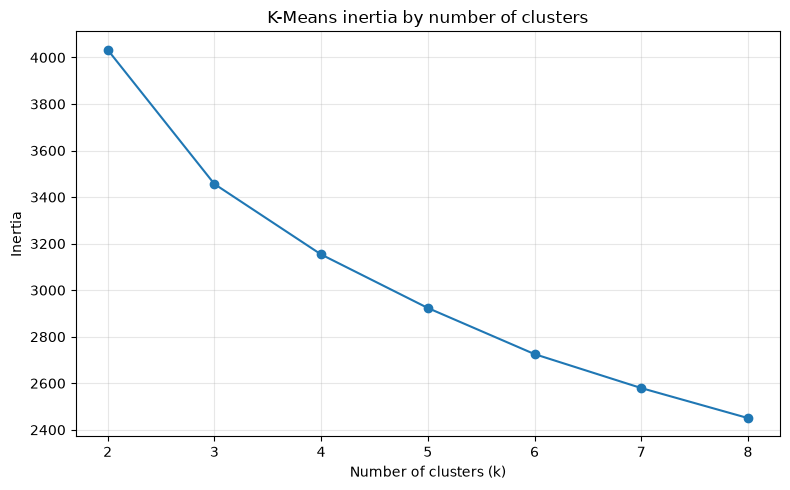

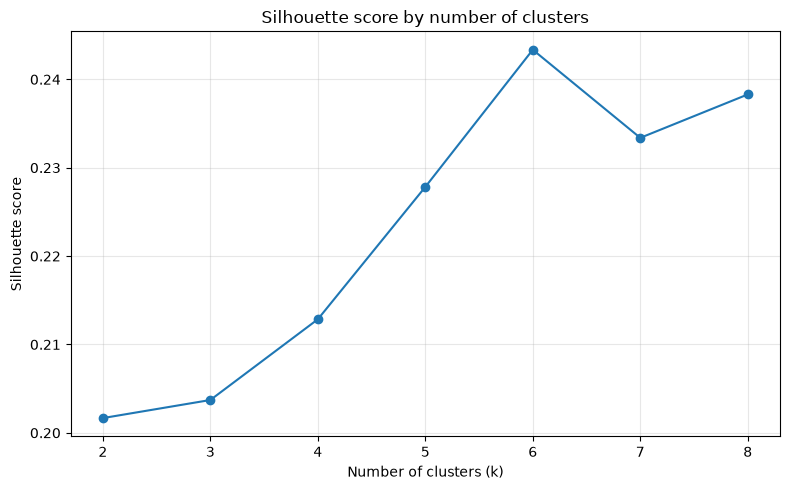

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(evaluation_df["k"], evaluation_df["inertia"], marker="o")
ax.set(title="K-Means inertia by number of clusters", xlabel="Number of clusters (k)", ylabel="Inertia")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "clustering_k_selection_inertia.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(evaluation_df["k"], evaluation_df["silhouette_score"], marker="o")
ax.set(title="Silhouette score by number of clusters", xlabel="Number of clusters (k)", ylabel="Silhouette score")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "clustering_k_selection_silhouette.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Select and fit the final solution
The notebook selects the k with the highest sampled silhouette score as a transparent starting rule. Inspect cluster sizes and profiles before presenting findings; a high score alone does not establish substantive meaning.

In [9]:
best_k = int(evaluation_df.loc[evaluation_df["silhouette_score"].idxmax(), "k"])
final_model = models[best_k]
analysis_df = analysis_df.reset_index(drop=True)
analysis_df["Cluster"] = final_model.labels_
print("Selected k:", best_k)
display(analysis_df["Cluster"].value_counts().sort_index().rename("district_year_observations").to_frame())

Selected k: 6


,district_year_observations
Cluster,
0,3325
1,662
2,3063
3,1550
4,340
5,865


## 9. Profile clusters using original crop shares
For each cluster, calculate average crop shares. Cluster numbers are arbitrary labels, not rankings.

In [10]:
cluster_crop_profiles = analysis_df.groupby("Cluster")[crop_columns].mean()
top_crop_rows = []
for cluster_id, row in cluster_crop_profiles.iterrows():
    for rank, (crop_name, share) in enumerate(row.sort_values(ascending=False).head(10).items(), start=1):
        top_crop_rows.append({"Cluster": int(cluster_id), "Rank": rank, "Crop": crop_name, "Mean_Area_Share": float(share)})
top_crops_by_cluster = pd.DataFrame(top_crop_rows)
display(top_crops_by_cluster)

,Cluster,Rank,Crop,Mean_Area_Share
0,0,1,Rice,0.696254
1,0,2,Maize,0.055434
2,0,3,Rapeseed &Mustard,0.023091
3,0,4,Urad,0.017722
4,0,5,Small millets,0.017001
5,0,6,Potato,0.015300
6,0,7,Moong(Green Gram),0.012775
7,0,8,Wheat,0.012014
8,0,9,Sugarcane,0.010676
9,0,10,Groundnut,0.010480


## 10. Add diversification metrics for interpretation
The Stage 3 metrics are joined for profiling only; they are not used as clustering inputs.

In [16]:
feature_df = pd.read_csv(FEATURES_PATH)
metric_candidates = [
    "crop_richness",
    "shannon_entropy",
    "normalized_shannon_evenness",
    "hhi_concentration",
    "simpson_diversity",
    "effective_number_of_crops",
    "top_1_crop_share",
    "top_3_crop_share"
]
available_metrics = [c for c in metric_candidates if c in feature_df.columns]
join_cols = ["State_Name", "District_Name", "Crop_Year"]
clustered_features = analysis_df[join_cols + ["Cluster"]].merge(
    feature_df[join_cols + available_metrics], on=join_cols, how="left", validate="one_to_one"
)
print("Available metrics:", available_metrics)
if available_metrics:
    cluster_summary = clustered_features.groupby("Cluster")[available_metrics].mean().round(4)
    display(cluster_summary)
else:
    print("No expected metric names found. Crop-share profiles remain available.")

Available metrics: ['crop_richness', 'shannon_entropy', 'normalized_shannon_evenness', 'hhi_concentration', 'simpson_diversity', 'effective_number_of_crops', 'top_1_crop_share', 'top_3_crop_share']


,crop_richness,shannon_entropy,normalized_shannon_evenness,hhi_concentration,simpson_diversity,effective_number_of_crops,top_1_crop_share,top_3_crop_share
Cluster,,,,,,,,
0,20.4217,1.0888,0.3804,0.5487,0.4513,3.3357,0.7020,0.8815
1,22.5650,1.6946,0.5557,0.2625,0.7375,5.8421,0.3870,0.7553
2,20.3314,1.4404,0.4948,0.3325,0.6675,4.4910,0.4528,0.8541
3,26.3065,2.0175,0.6274,0.2207,0.7793,8.1458,0.3575,0.6472
4,14.7294,1.3650,0.5194,0.3881,0.6119,4.2099,0.5485,0.8371
5,25.3827,1.7782,0.5644,0.2445,0.7555,6.2385,0.3778,0.7393


## 11. Compare crop profiles with a heatmap

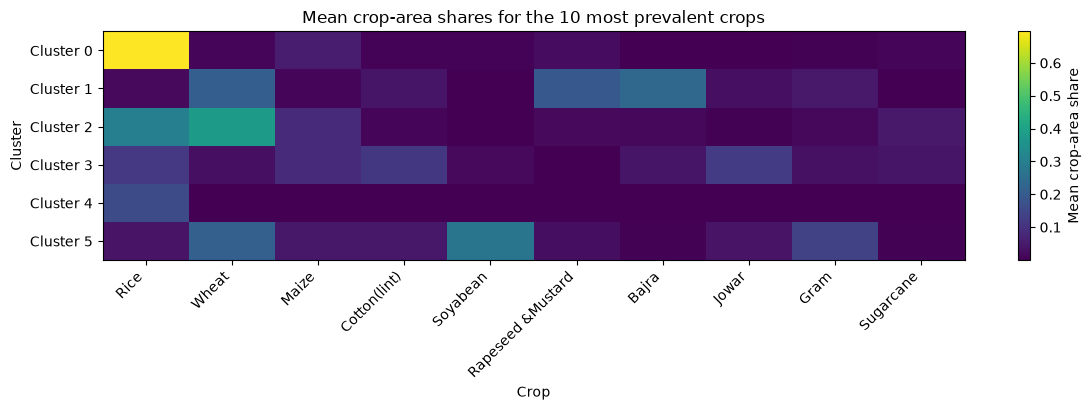

In [12]:
overall_top_crops = analysis_df[crop_columns].mean().sort_values(ascending=False).head(10).index.tolist()
heatmap_data = cluster_crop_profiles[overall_top_crops]
fig, ax = plt.subplots(figsize=(12, max(4, 0.7 * len(heatmap_data))))
im = ax.imshow(heatmap_data.to_numpy(), aspect="auto")
ax.set_xticks(range(len(overall_top_crops)))
ax.set_xticklabels(overall_top_crops, rotation=45, ha="right")
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels([f"Cluster {i}" for i in heatmap_data.index])
ax.set(title="Mean crop-area shares for the 10 most prevalent crops", xlabel="Crop", ylabel="Cluster")
fig.colorbar(im, ax=ax, label="Mean crop-area share")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "clustering_crop_profile_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. PCA visualisation
PCA reduces the transformed crop-share matrix to two dimensions for plotting only. Clustering was fitted using the full transformed feature space.

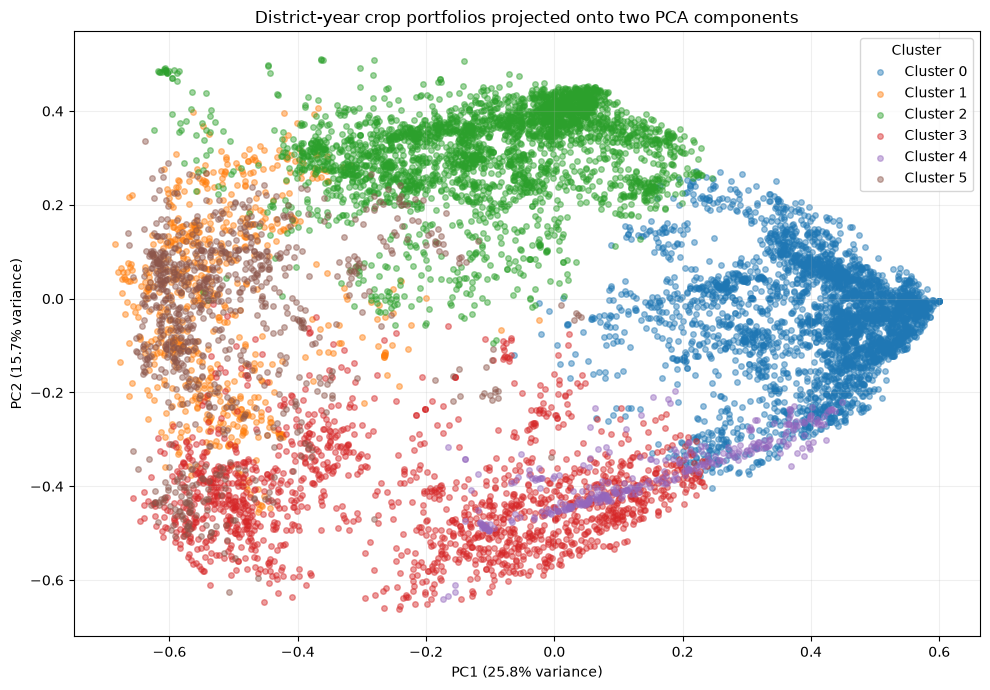

Variance explained by two components: 0.4153


In [13]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_hellinger)
plot_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Cluster": analysis_df["Cluster"].astype(str)})
fig, ax = plt.subplots(figsize=(10, 7))
for label in sorted(plot_df["Cluster"].unique(), key=int):
    subset = plot_df[plot_df["Cluster"] == label]
    ax.scatter(subset["PC1"], subset["PC2"], label=f"Cluster {label}", alpha=0.45, s=16)
ax.set(title="District-year crop portfolios projected onto two PCA components",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.legend(title="Cluster")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "clustering_pca_visualisation.png", dpi=300, bbox_inches="tight")
plt.show()
print("Variance explained by two components:", round(pca.explained_variance_ratio_.sum(), 4))

## 13. Export clustering results

In [17]:
assignments_path = DATA_DIR / "district_year_cluster_assignments.csv"
profiles_path = DATA_DIR / "cluster_crop_profiles.csv"
top_crops_path = REPORT_DIR / "cluster_top_crops.csv"
summary_path = REPORT_DIR / "cluster_summary.csv"
evaluation_path = REPORT_DIR / "cluster_model_evaluation.csv"

analysis_df.to_csv(assignments_path, index=False)
cluster_crop_profiles.to_csv(profiles_path)
top_crops_by_cluster.to_csv(top_crops_path, index=False)
evaluation_df.to_csv(evaluation_path, index=False)

cluster_sizes = analysis_df["Cluster"].value_counts().sort_index().rename("Observations")
export_summary = cluster_sizes.to_frame()
if available_metrics:
    export_summary = export_summary.join(cluster_summary)
export_summary.to_csv(summary_path)

for path in [assignments_path, profiles_path, top_crops_path, summary_path, evaluation_path]:
    print("Saved:", path.relative_to(PROJECT_ROOT))

Saved: data\processed\district_year_cluster_assignments.csv
Saved: data\processed\cluster_crop_profiles.csv
Saved: outputs\reports\cluster_top_crops.csv
Saved: outputs\reports\cluster_summary.csv
Saved: outputs\reports\cluster_model_evaluation.csv


## 14. Final validation

In [15]:
assert analysis_df["Cluster"].notna().all()
assert analysis_df["Cluster"].nunique() == best_k
assert not (analysis_df["Crop_Year"] == 2015).any()
assert len(analysis_df) == len(crop_matrix.loc[crop_matrix["Crop_Year"].between(1997, 2014)])
for path in [assignments_path, profiles_path, top_crops_path, summary_path, evaluation_path]:
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty output: {path}"
assignments_check = pd.read_csv(assignments_path)
assert len(assignments_check) == len(analysis_df)
assert assignments_check["Cluster"].nunique() == best_k
print("All validation checks passed.")
print("District-year observations clustered:", len(assignments_check))
print("Number of clusters:", best_k)

All validation checks passed.
District-year observations clustered: 9805
Number of clusters: 6


## 15. Interpretation notes for your report

Use the actual outputs from this notebook. Do not invent descriptive cluster names before inspecting their top-crop profiles.

Report:
1. The selected k and its silhouette score.
2. The number of district-year observations in each cluster.
3. Each cluster's leading crop shares and average diversification metrics.
4. That clusters represent similarity in reported crop-area composition, not agricultural performance or crop suitability.
5. The limitations: incomplete 2015 coverage, unbalanced 1997–2014 observations, possible district-name/boundary changes, and gross reported crop area across seasons.

**Do not claim** that a cluster is more successful, productive, sustainable, or recommended. This analysis does not test those claims.